# Phase 2: Model Robustness and Adversarial Testing

## Objectives
- Establish a clean baseline.
- Test Gaussian noise, rotation, and brightness variations.
- Evaluate an FGSM adversarial attack.
- Compare accuracy degradation and inspect failures.
- Save reproducible metrics and visualizations.

In [2]:
import json
import random
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF

SEED = 42
BATCH_SIZE = 128

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_PATH = PROJECT_ROOT / "models" / "mnist_baseline.pth"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", PROJECT_ROOT)
print("Device:", device)
print("Model exists:", MODEL_PATH.exists())

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

Project root: c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project
Device: cpu
Model exists: True


In [3]:
class MNISTMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


model = MNISTMLP().to(device)
state_dict = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)
model.load_state_dict(state_dict)
model.eval()

transform = transforms.ToTensor()

test_dataset = datasets.MNIST(
    root=str(PROJECT_ROOT / "data"),
    train=False,
    download=True,
    transform=transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Test images:", len(test_dataset))
print("Model loaded successfully")

Test images: 10000
Model loaded successfully


In [4]:
criterion = nn.CrossEntropyLoss()

def evaluate_model(model, loader, transform_batch=None):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    all_predictions = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if transform_batch is not None:
            images = transform_batch(images)

        with torch.no_grad():
            logits = model(images)
            loss = criterion(logits, labels)

        total_loss += loss.item() * labels.size(0)
        predictions = logits.argmax(dim=1)

        total_correct += (predictions == labels).sum().item()
        total_samples += labels.size(0)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    return {
        "accuracy": total_correct / total_samples,
        "loss": total_loss / total_samples,
        "predictions": all_predictions,
        "labels": all_labels
    }


clean_result = evaluate_model(model, test_loader)

print(f"Clean accuracy: {clean_result['accuracy']:.2%}")
print(f"Clean loss: {clean_result['loss']:.4f}")

Clean accuracy: 97.76%
Clean loss: 0.0782


In [5]:
def add_gaussian_noise(images, sigma):
    noise = torch.randn_like(images) * sigma
    return (images + noise).clamp(0.0, 1.0)


def rotate_images(images, angle):
    # Batch shape: [N, 1, 28, 28]
    return torch.stack([
        TF.rotate(image, angle=angle, fill=0.0)
        for image in images
    ])


def change_brightness(images, factor):
    return (images * factor).clamp(0.0, 1.0)

In [6]:
results = [{
    "experiment": "Clean baseline",
    "condition": "none",
    "accuracy": clean_result["accuracy"],
    "loss": clean_result["loss"]
}]

experiments = [
    ("Gaussian noise", "sigma=0.1",
     lambda x: add_gaussian_noise(x, 0.1)),
    ("Gaussian noise", "sigma=0.2",
     lambda x: add_gaussian_noise(x, 0.2)),
    ("Gaussian noise", "sigma=0.3",
     lambda x: add_gaussian_noise(x, 0.3)),
    ("Rotation", "angle=-15",
     lambda x: rotate_images(x, -15)),
    ("Rotation", "angle=15",
     lambda x: rotate_images(x, 15)),
    ("Rotation", "angle=30",
     lambda x: rotate_images(x, 30)),
    ("Brightness", "factor=0.5",
     lambda x: change_brightness(x, 0.5)),
    ("Brightness", "factor=0.75",
     lambda x: change_brightness(x, 0.75)),
    ("Brightness", "factor=1.25",
     lambda x: change_brightness(x, 1.25)),
]

for experiment_name, condition, transform_batch in experiments:
    evaluation = evaluate_model(
        model, test_loader, transform_batch=transform_batch
    )

    results.append({
        "experiment": experiment_name,
        "condition": condition,
        "accuracy": evaluation["accuracy"],
        "loss": evaluation["loss"]
    })

    print(
        f"{experiment_name:15} | {condition:12} | "
        f"accuracy={evaluation['accuracy']:.2%} | "
        f"loss={evaluation['loss']:.4f}"
    )

robustness_df = pd.DataFrame(results)
robustness_df["accuracy_drop_percentage_points"] = (
    clean_result["accuracy"] - robustness_df["accuracy"]
) * 100

robustness_df

Gaussian noise  | sigma=0.1    | accuracy=96.13% | loss=0.1238
Gaussian noise  | sigma=0.2    | accuracy=86.22% | loss=0.4434
Gaussian noise  | sigma=0.3    | accuracy=65.66% | loss=1.2873
Rotation        | angle=-15    | accuracy=92.46% | loss=0.2816
Rotation        | angle=15     | accuracy=93.66% | loss=0.2328
Rotation        | angle=30     | accuracy=75.26% | loss=1.0357
Brightness      | factor=0.5   | accuracy=97.77% | loss=0.0925
Brightness      | factor=0.75  | accuracy=97.80% | loss=0.0745
Brightness      | factor=1.25  | accuracy=97.71% | loss=0.0814


,experiment,condition,accuracy,loss,accuracy_drop_percentage_points
0,Clean baseline,none,0.9776,0.078247,0.00
1,Gaussian noise,sigma=0.1,0.9613,0.123807,1.63
2,Gaussian noise,sigma=0.2,0.8622,0.443353,11.54
3,Gaussian noise,sigma=0.3,0.6566,1.287258,32.10
4,Rotation,angle=-15,0.9246,0.281600,5.30
5,Rotation,angle=15,0.9366,0.232786,4.10
6,Rotation,angle=30,0.7526,1.035677,22.50
7,Brightness,factor=0.5,0.9777,0.092536,-0.01
8,Brightness,factor=0.75,0.9780,0.074496,-0.04
9,Brightness,factor=1.25,0.9771,0.081385,0.05


In [7]:
def evaluate_fgsm(model, loader, epsilon):
    model.eval()

    total_correct = 0
    total_samples = 0
    total_loss = 0.0

    for images, labels in loader:
        images = images.to(device).detach().requires_grad_(True)
        labels = labels.to(device)

        model.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)

        model.zero_grad(set_to_none=True)
        loss.backward()

        # Create the adversarial examples using input gradients.
        perturbation = epsilon * images.grad.sign()
        adversarial_images = (
            images.detach() + perturbation
        ).clamp(0.0, 1.0)

        with torch.no_grad():
            adversarial_logits = model(adversarial_images)
            adversarial_loss = criterion(adversarial_logits, labels)
            predictions = adversarial_logits.argmax(dim=1)

        total_correct += (predictions == labels).sum().item()
        total_samples += labels.size(0)
        total_loss += adversarial_loss.item() * labels.size(0)

    return {
        "accuracy": total_correct / total_samples,
        "loss": total_loss / total_samples
    }


fgsm_results = []

for epsilon in [0.05, 0.1, 0.2]:
    evaluation = evaluate_fgsm(model, test_loader, epsilon)

    fgsm_results.append({
        "experiment": "FGSM",
        "condition": f"epsilon={epsilon}",
        "accuracy": evaluation["accuracy"],
        "loss": evaluation["loss"]
    })

    print(
        f"FGSM epsilon={epsilon:.2f} | "
        f"accuracy={evaluation['accuracy']:.2%} | "
        f"loss={evaluation['loss']:.4f}"
    )

fgsm_df = pd.DataFrame(fgsm_results)
fgsm_df["accuracy_drop_percentage_points"] = (
    clean_result["accuracy"] - fgsm_df["accuracy"]
) * 100

fgsm_df

FGSM epsilon=0.05 | accuracy=55.89% | loss=1.7717
FGSM epsilon=0.10 | accuracy=9.88% | loss=6.6495
FGSM epsilon=0.20 | accuracy=0.46% | loss=15.3325


,experiment,condition,accuracy,loss,accuracy_drop_percentage_points
0,FGSM,epsilon=0.05,0.5589,1.771678,41.87
1,FGSM,epsilon=0.1,0.0988,6.649501,87.88
2,FGSM,epsilon=0.2,0.0046,15.332537,97.30


,experiment,condition,accuracy,loss,accuracy_drop_percentage_points
0,Clean baseline,none,97.76%,0.0782,0.00
1,Gaussian noise,sigma=0.1,96.13%,0.1238,1.63
2,Gaussian noise,sigma=0.2,86.22%,0.4434,11.54
3,Gaussian noise,sigma=0.3,65.66%,1.2873,32.10
4,Rotation,angle=-15,92.46%,0.2816,5.30
5,Rotation,angle=15,93.66%,0.2328,4.10
6,Rotation,angle=30,75.26%,1.0357,22.50
7,Brightness,factor=0.5,97.77%,0.0925,-0.01
8,Brightness,factor=0.75,97.80%,0.0745,-0.04
9,Brightness,factor=1.25,97.71%,0.0814,0.05


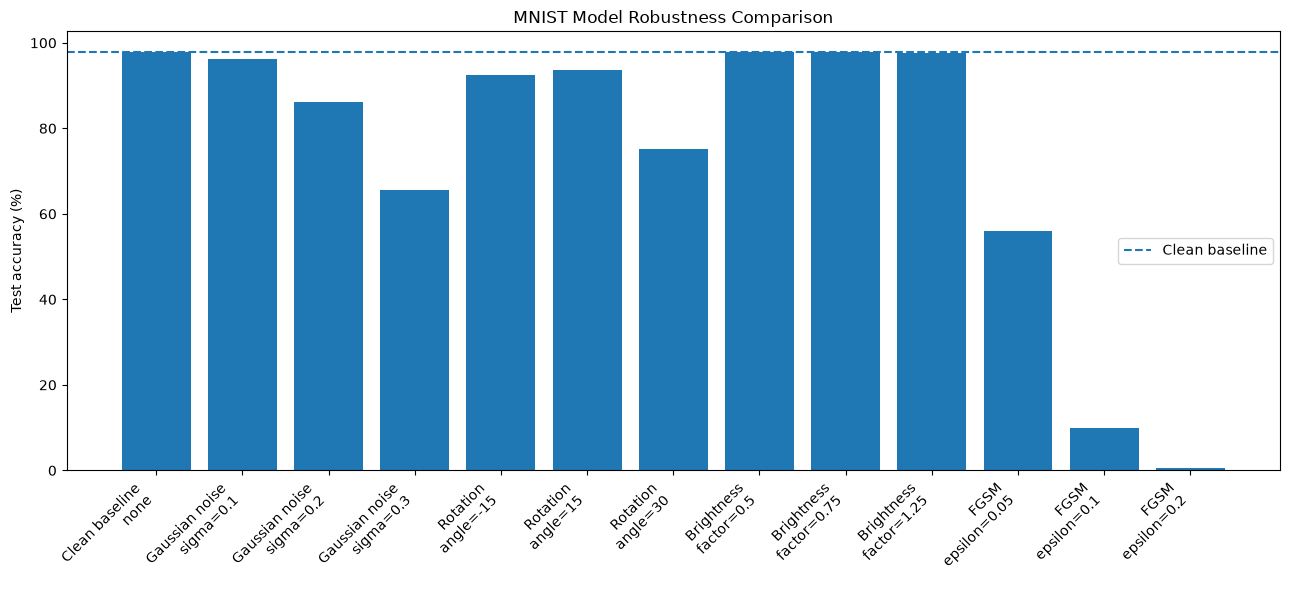

In [8]:
all_results_df = pd.concat(
    [robustness_df, fgsm_df],
    ignore_index=True
)

display(
    all_results_df.style.format({
        "accuracy": "{:.2%}",
        "loss": "{:.4f}",
        "accuracy_drop_percentage_points": "{:.2f}"
    })
)

plt.figure(figsize=(13, 6))

labels = (
    all_results_df["experiment"] + "\n" +
    all_results_df["condition"]
)

plt.bar(labels, all_results_df["accuracy"] * 100)
plt.axhline(
    clean_result["accuracy"] * 100,
    linestyle="--",
    label="Clean baseline"
)

plt.ylabel("Test accuracy (%)")
plt.title("MNIST Model Robustness Comparison")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()

robustness_chart_path = REPORTS_DIR / "robustness_accuracy_comparison.png"
plt.savefig(robustness_chart_path, dpi=150, bbox_inches="tight")
plt.show()

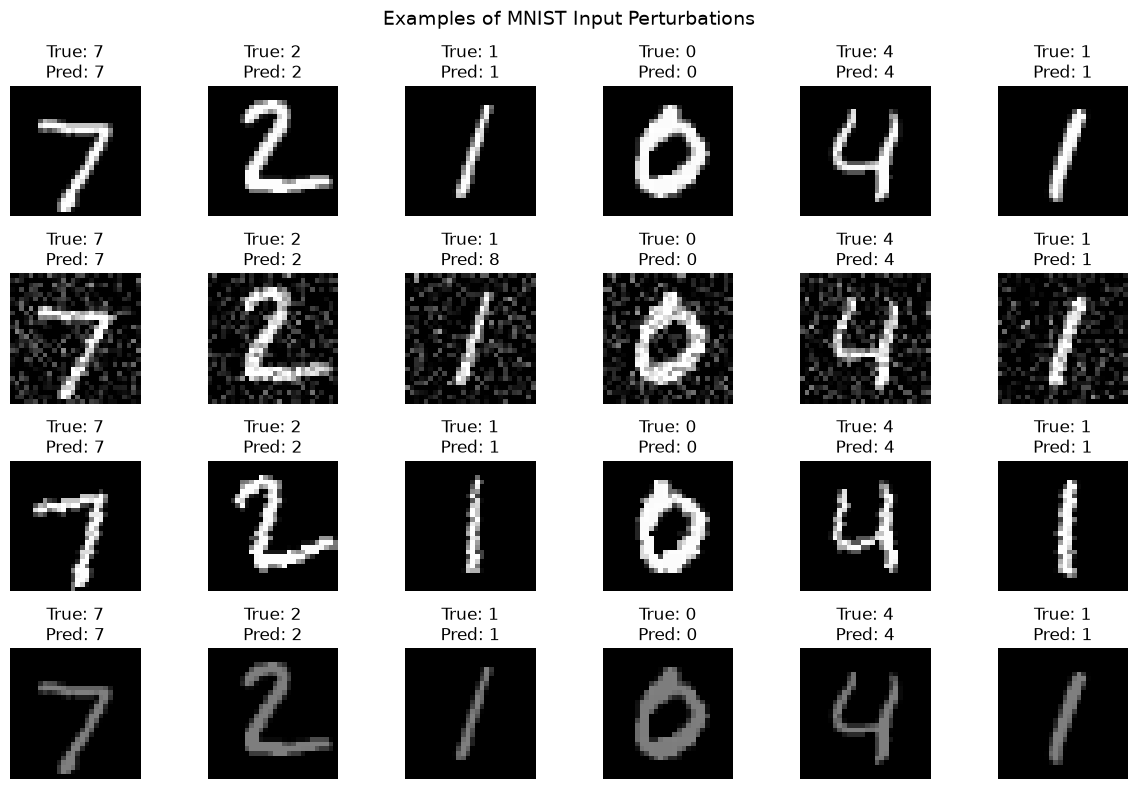

In [10]:
images, labels = next(iter(test_loader))
images = images[:6].to(device)
labels = labels[:6].to(device)

example_noise = add_gaussian_noise(images, 0.2)
example_rotation = rotate_images(images, 15)
example_brightness = change_brightness(images, 0.5)

model.eval()

with torch.no_grad():
    clean_predictions = model(images).argmax(dim=1)
    noise_predictions = model(example_noise).argmax(dim=1)
    rotation_predictions = model(example_rotation).argmax(dim=1)
    brightness_predictions = model(example_brightness).argmax(dim=1)

image_groups = [
    ("Clean", images, clean_predictions),
    ("Gaussian noise", example_noise, noise_predictions),
    ("Rotation +15°", example_rotation, rotation_predictions),
    ("Brightness ×0.5", example_brightness, brightness_predictions)
]

fig, axes = plt.subplots(4, 6, figsize=(12, 8))

for row, (title, batch, predictions) in enumerate(image_groups):
    for col in range(6):
        axes[row, col].imshow(
            batch[col, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1
        )
        axes[row, col].set_title(
            f"True: {labels[col].item()}\nPred: {predictions[col].item()}"
        )
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(title, fontsize=10)

plt.suptitle("Examples of MNIST Input Perturbations", fontsize=14)
plt.tight_layout()

examples_path = REPORTS_DIR / "robustness_examples.png"
plt.savefig(examples_path, dpi=150, bbox_inches="tight")
plt.show()

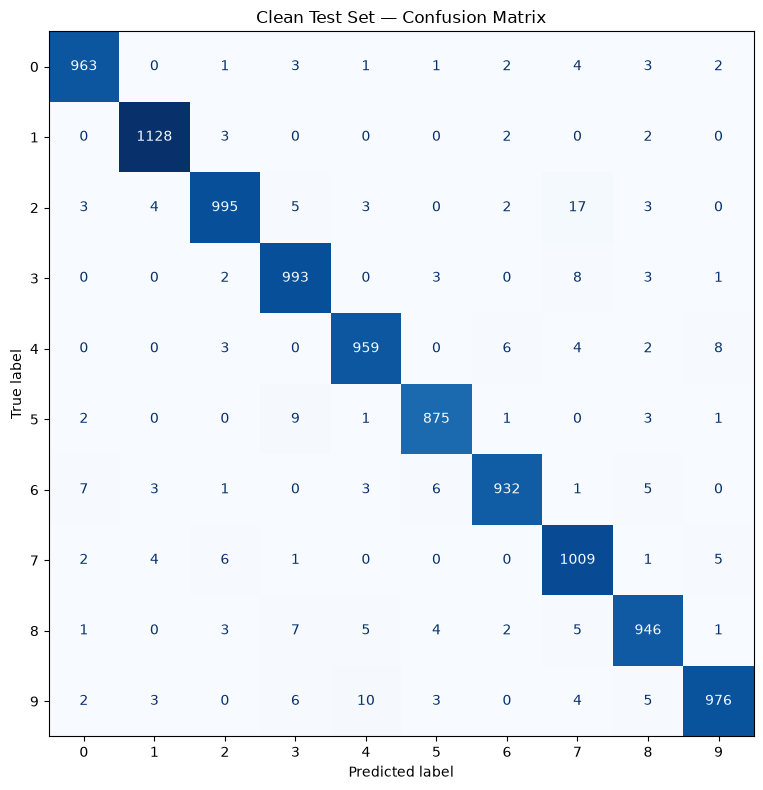

Lowest clean-test F1 scores:
Digit 7: F1 = 0.9702
Digit 8: F1 = 0.9718
Digit 2: F1 = 0.9726


In [11]:
clean_report = classification_report(
    clean_result["labels"],
    clean_result["predictions"],
    output_dict=True,
    zero_division=0
)

clean_cm = confusion_matrix(
    clean_result["labels"],
    clean_result["predictions"]
)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(
    confusion_matrix=clean_cm,
    display_labels=list(range(10))
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Clean Test Set — Confusion Matrix")
plt.tight_layout()

clean_cm_path = REPORTS_DIR / "phase2_clean_confusion_matrix.png"
plt.savefig(clean_cm_path, dpi=150, bbox_inches="tight")
plt.show()

weakest_classes = sorted(
    [
        (digit, clean_report[str(digit)]["f1-score"])
        for digit in range(10)
    ],
    key=lambda item: item[1]
)

print("Lowest clean-test F1 scores:")
for digit, score in weakest_classes[:3]:
    print(f"Digit {digit}: F1 = {score:.4f}")

In [12]:
csv_path = REPORTS_DIR / "robustness_metrics.csv"
json_path = REPORTS_DIR / "robustness_metrics.json"

all_results_df.to_csv(csv_path, index=False)

report = {
    "experiment": "MNIST Phase 2 - Robustness and Adversarial Testing",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "seed": SEED,
    "model": "Phase 1 saved MNIST MLP",
    "test_samples": len(test_dataset),
    "clean_baseline": {
        "accuracy": clean_result["accuracy"],
        "loss": clean_result["loss"],
        "correct": int(
            round(clean_result["accuracy"] * len(test_dataset))
        )
    },
    "experiments": all_results_df.to_dict(orient="records"),
    "notes": [
        "Gaussian noise is randomly sampled; repeatability requires fixed perturbations.",
        "Rotation and brightness settings are experimental stress conditions.",
        "FGSM is an untargeted white-box adversarial attack.",
        "No adversarial training or model fine-tuning was performed."
    ]
}

with open(json_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=2)

print("Saved:")
print(csv_path)
print(json_path)
print(robustness_chart_path)
print(examples_path)
print(clean_cm_path)

Saved:
c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\robustness_metrics.csv
c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\robustness_metrics.json
c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\robustness_accuracy_comparison.png
c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\robustness_examples.png
c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\phase2_clean_confusion_matrix.png


In [13]:
csv_path = REPORTS_DIR / "robustness_metrics.csv"
json_path = REPORTS_DIR / "robustness_metrics.json"

all_results_df.to_csv(csv_path, index=False)

report = {
    "experiment": "MNIST Phase 2 - Robustness and Adversarial Testing",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "seed": SEED,
    "model": "Phase 1 saved MNIST MLP",
    "test_samples": len(test_dataset),
    "clean_baseline": {
        "accuracy": clean_result["accuracy"],
        "loss": clean_result["loss"],
        "correct": int(
            round(clean_result["accuracy"] * len(test_dataset))
        )
    },
    "experiments": all_results_df.to_dict(orient="records"),
    "notes": [
        "Gaussian noise is randomly sampled; repeatability requires fixed perturbations.",
        "Rotation and brightness settings are experimental stress conditions.",
        "FGSM is an untargeted white-box adversarial attack.",
        "No adversarial training or model fine-tuning was performed."
    ]
}

with open(json_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=2)

print("Saved:")
print(csv_path)
print(json_path)
print(robustness_chart_path)
print(examples_path)
print(clean_cm_path)

Saved:
c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\robustness_metrics.csv
c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\robustness_metrics.json
c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\robustness_accuracy_comparison.png
c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\robustness_examples.png
c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\phase2_clean_confusion_matrix.png


In [14]:
exact_correct = sum(
    p == y
    for p, y in zip(
        clean_result["predictions"],
        clean_result["labels"]
    )
)

print(f"Exact clean correct predictions: {exact_correct}")
print(f"Exact clean incorrect predictions: {len(test_dataset) - exact_correct}")

Exact clean correct predictions: 9776
Exact clean incorrect predictions: 224


In [15]:
baseline_accuracy = clean_result["accuracy"]

report_lines = [
    "# Phase 2: Model Robustness and Adversarial Testing",
    "",
    f"Generated (UTC): {datetime.now(timezone.utc).isoformat()}",
    "",
    "## Objective",
    "Evaluate the Phase 1 MNIST MLP under image perturbations and FGSM.",
    "",
    "## Clean Baseline",
    f"- Test accuracy: {baseline_accuracy:.2%}",
    f"- Test loss: {clean_result['loss']:.4f}",
    f"- Correct predictions: {exact_correct}/{len(test_dataset)}",
    "",
    "## Experiment Results",
    "",
    "| Experiment | Condition | Accuracy | Loss | Accuracy drop (percentage points) |",
    "|---|---|---:|---:|---:|",
]

for _, row in all_results_df.iterrows():
    report_lines.append(
        f"| {row['experiment']} | {row['condition']} | "
        f"{row['accuracy']:.2%} | {row['loss']:.4f} | "
        f"{row['accuracy_drop_percentage_points']:.2f} |"
    )

report_lines += [
    "",
    "## Artifacts",
    "- `robustness_metrics.csv`",
    "- `robustness_metrics.json`",
    "- `robustness_accuracy_comparison.png`",
    "- `robustness_examples.png`",
    "- `phase2_clean_confusion_matrix.png`",
    "",
    "## Limitations",
    "- Results apply to the tested MNIST test set and perturbation strengths.",
    "- Random noise results may vary between runs.",
    "- FGSM results do not represent all possible adversarial attacks.",
    "- The model was evaluated without adversarial retraining.",
]

report_path = REPORTS_DIR / "phase2_robustness_report.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")

print("Report saved:", report_path)

Report saved: c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\phase2_robustness_report.md


In [16]:
assert len(all_results_df) == 13, "Expected 1 clean baseline + 9 transformations + 3 FGSM tests"
assert all_results_df["accuracy"].between(0, 1).all()
assert all_results_df["loss"].ge(0).all()

expected_artifacts = [
    "robustness_metrics.csv",
    "robustness_metrics.json",
    "robustness_accuracy_comparison.png",
    "robustness_examples.png",
    "phase2_clean_confusion_matrix.png",
    "phase2_robustness_report.md",
]

for filename in expected_artifacts:
    path = REPORTS_DIR / filename
    print(f"{'OK' if path.exists() else 'MISSING'}: {filename}")

OK: robustness_metrics.csv
OK: robustness_metrics.json
OK: robustness_accuracy_comparison.png
OK: robustness_examples.png
OK: phase2_clean_confusion_matrix.png
OK: phase2_robustness_report.md
